# 2D wave equation on the unit square

Solves the hyperbolic PDE
$$
\frac{\partial^2 u}{\partial t^2} = \nabla^2 u, \qquad (t, \mathbf{x}) \in (0, T] \times \Omega, \qquad \Omega = (0,1)^2,
$$
with zero Dirichlet boundary conditions (a clamped membrane), an initial displacement $u(0,\mathbf{x}) = u_0(\mathbf{x})$ given by a Gaussian pulse, and zero initial velocity $\partial_t u(0, \mathbf{x}) = 0$.

Space is discretized with the 5-point Laplacian $L$ and time with the explicit leapfrog (central difference) scheme
$$
\mathbf{u}^{n+1} = 2\mathbf{u}^n - \mathbf{u}^{n-1} + \Delta t^2 L \mathbf{u}^n,
$$
which is stable under the CFL condition $\Delta t \le h / \sqrt{2}$. The first step uses a Taylor expansion with the initial velocity $\mathbf{v}_0$:
$\mathbf{u}^1 = \mathbf{u}^0 + \Delta t\, \mathbf{v}_0 + \tfrac{\Delta t^2}{2} L \mathbf{u}^0$.

In [1]:
import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image

In [2]:
def laplacian_2d(N, h):
    """5-point finite difference Laplacian on an N x N grid of interior
    nodes of the unit square, with zero Dirichlet boundary conditions.
    Unknowns are ordered row by row (x fastest)."""
    e = np.ones(N)
    D2 = sp.diags([e[:-1], -2 * e, e[:-1]], [-1, 0, 1]) / h**2
    I = sp.identity(N)
    return (sp.kron(I, D2) + sp.kron(D2, I)).tocsc()

In [3]:
# grid of N x N interior nodes on the unit square Omega = (0,1)^2
N = 80
h = 1.0 / (N + 1)
x = np.linspace(h, 1 - h, N)
X, Y = np.meshgrid(x, x)
L = laplacian_2d(N, h)
print(f"N = {N}, h = {h:.4f}, number of unknowns = {N**2}")

N = 80, h = 0.0123, number of unknowns = 6400


In [4]:
# initial displacement: Gaussian pulse off-center; zero initial velocity
u0 = np.exp(-((X - 0.35) ** 2 + (Y - 0.4) ** 2) / (2 * 0.05**2)).ravel()
v0 = np.zeros_like(u0)

# leapfrog time stepping with dt = 0.5 h (CFL limit is h / sqrt(2))
T = 1.5
dt = 0.5 * h
Nt = int(np.ceil(T / dt))
dt = T / Nt

u_prev = u0.copy()
u = u0 + dt * v0 + 0.5 * dt**2 * (L @ u0)
U = [u_prev.copy(), u.copy()]
for n in range(1, Nt):
    u_next = 2 * u - u_prev + dt**2 * (L @ u)
    u_prev, u = u, u_next
    U.append(u.copy())
U = np.array(U)
t = np.linspace(0, T, Nt + 1)
print(f"dt = {dt:.4f}, dt/h = {dt / h:.3f}, Nt = {Nt}")

dt = 0.0062, dt/h = 0.500, Nt = 243


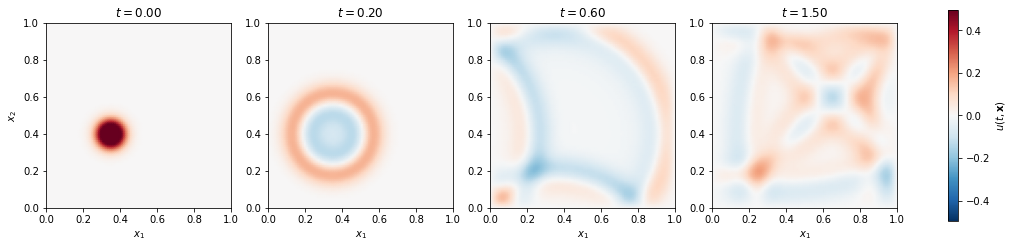

In [5]:
def with_boundary(u):
    """Embed interior values in an (N+2) x (N+2) array with zero boundary values."""
    U = np.zeros((N + 2, N + 2))
    U[1:-1, 1:-1] = u.reshape(N, N)
    return U


xb = np.linspace(0, 1, N + 2)


# four snapshots on a common symmetric color scale
snap_idx = [0, int(0.2 / dt), int(0.6 / dt), Nt]
vmax = 0.5 * np.abs(U).max()
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6), constrained_layout=True)
for ax, k in zip(axes, snap_idx):
    im = ax.pcolormesh(xb, xb, with_boundary(U[k]), cmap="RdBu_r",
                       vmin=-vmax, vmax=vmax, shading="gouraud")
    ax.set_aspect("equal")
    ax.set_title(f"$t = {t[k]:.2f}$")
    ax.set_xlabel("$x_1$")
axes[0].set_ylabel("$x_2$")
fig.colorbar(im, ax=axes, shrink=0.85, label="$u(t, \\mathbf{x})$")
fig.savefig("wave_2d_snapshots.png", dpi=200, bbox_inches="tight")
plt.show()

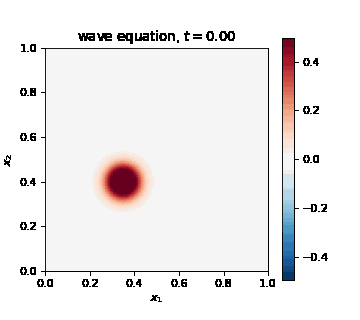

In [6]:
# animation of the evolution, saved as a gif
fig, ax = plt.subplots(figsize=(4.5, 4))
im = ax.pcolormesh(xb, xb, with_boundary(U[0]), cmap="RdBu_r",
                   vmin=-vmax, vmax=vmax, shading="gouraud")
ax.set_aspect("equal")
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
fig.colorbar(im, ax=ax)
title = ax.set_title("")
frames = range(0, Nt + 1, 2)


def update(k):
    im.set_array(with_boundary(U[k]).ravel())
    title.set_text(f"wave equation, $t = {t[k]:.2f}$")
    return im, title


anim = FuncAnimation(fig, update, frames=frames, blit=False)
anim.save("wave_2d.gif", writer=PillowWriter(fps=20), dpi=80)
plt.close(fig)
Image(filename="wave_2d.gif")